# 08 · Partial distance correlation: separating Doppler shifts from shape changes

**What you'll learn**

- why an RV periodogram cannot tell a planet from stellar activity
- the partial distance correlation (Székely & Rizzo 2014): a dependence with the part a third
  quantity explains removed
- the **shift** and **shape** partial periodograms (Binnenfeld, Shahaf & Zucker 2022, A&A 659,
  A189), which split a planet around an active star into its two periods

Every step is a public function on plain arrays (`sparta.pdc`, `unicor`, `phoenix_spectrum`);
the last cell checks the same numbers with the `PeriodicityDetector` object.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle

from sparta.instruments.simulated import upper_envelope
from sparta.pdc import (inner_prod, norm_z, partial_centering, pdc_power, pdc_power_level, pdc_pvalue,
                        scalar_distance_matrix, spectral_distance_matrix, unbiased_u_centering)
from sparta.plotting import (EXTRA_COLOR, GREY, apply_style, plot_curve, plot_extra, plot_model,
                             plot_points)
from sparta.preprocess import resample_to_log_grid
from sparta.template import phoenix_spectrum
from unicor import ccf_order, dsp

# Apply the SPARTA figure style
apply_style()

# Periodogram power at the grid frequency nearest a given period
def power_at(freqs, power, period):
    """Power at the grid frequency closest to 1/period (period in days)."""
    return power[np.argmin(np.abs(freqs - 1 / period))]

## 1. The problem

An RV is the position of the CCF peak. It moves when the star moves, and also when the lines
change *shape* (spots, convective blueshift, temperature, blends): in notebook 07 a temperature
swing with no motion gave RVs with an 11 m/s amplitude at its period. A periodogram of the RVs
(notebook 06) cannot tell such a leak from a planet, and USuRPER (notebook 07) sees every change
of the spectra without saying which is a shift. Binnenfeld et al. build one distance per pair of
epochs for the shift and one for the shape, and ask each for the periodicity that the other
cannot explain.

## 2. The idea: partial distance correlation

The PDC (notebook 06) U-centres two distance matrices (`unbiased_u_centering`): $a$, of the
quantity searched, and $b$, the phase distances. Its power is the cosine of $\tilde A$ and
$\tilde B$ under the U-centred inner product (`inner_prod`;
[periodograms § PDC](../../docs/periodograms.md#pdc-phase-distance-correlation-zucker-2018)):

$$\mathrm{dCor}(a, b) = \frac{(\tilde A \cdot \tilde B)}{|\tilde A|\,|\tilde B|}.$$

The **partial** version removes from both their projection on a *control* $\tilde C$
(`norm_z`) and takes the cosine of what is left:

$$P(\tilde A) = \tilde A - \frac{(\tilde A \cdot \tilde C)}{(\tilde C \cdot \tilde C)}\,\tilde C,
\qquad
\mathrm{pdCor}(a, b;\, c) = \frac{\bigl(P(\tilde A) \cdot P(\tilde B)\bigr)}{|P(\tilde A)|\,|P(\tilde B)|}.$$

If $a$ and $b$ are related only through $c$, little is left (and it can be negative).

The **shift distance** is $|v_i - v_j|$ of the measured RVs (`scalar_distance_matrix`); the
**shape distance** is the USuRPER chord distance (`spectral_distance_matrix`) between the spectra
shifted back to rest by their own RVs, so a pure Doppler shift leaves none. The *shift*
periodogram searches the shift distance controlling for the shape distance; the *shape*
periodogram the reverse. `partial_centering(a, c)` returns $P(\tilde A)$ and $\tilde C$, and
`pdc_power(times, freqs, P(Ã), control=C̃)` projects every phase matrix the same way
([periodograms § partial periodograms](../../docs/periodograms.md#partial-periodograms-shift-and-shape-binnenfeld-et-al-2022)).

## 3. A toy: three numbers per epoch

First, three plain variables. $x$ and $y$ both follow $z$ (plus independent noise) and are
related to each other *only* through it. As a contrast, $y'$ follows $x$ itself. The helpers
below are the two formulas above, written with the `sparta.pdc` functions.

In [2]:
# Distance correlation of two distance matrices
def dcor(a, b):
    n = len(a)
    A, B = unbiased_u_centering(a, n), unbiased_u_centering(b, n)
    return inner_prod(A, B) / np.sqrt(inner_prod(A, A) * inner_prod(B, B))

# Partial distance correlation of a and b, controlling for c
def pdcor(a, b, c):
    A, C = partial_centering(a, c)                  # Ã without its projection on C̃, and C̃
    B = norm_z(unbiased_u_centering(b, len(b)), C)  # the same for B̃
    return inner_prod(A, B) / np.sqrt(inner_prod(A, A) * inner_prod(B, B))

# Toy data: x and y both follow z; y' follows x directly
rng = np.random.default_rng(0)
z = rng.standard_normal(300)
x = z + 0.2 * rng.standard_normal(z.size)           # x and y follow z ...
y = z + 0.2 * rng.standard_normal(z.size)           # ... and nothing else
y_direct = x + 0.2 * rng.standard_normal(z.size)    # y' follows x itself
# One distance matrix per variable
dx, dy, dz, dyd = (scalar_distance_matrix(v) for v in (x, y, z, y_direct))
# Dependence with and without controlling for z
print(f"x, y  (related through z only): dCor = {dcor(dx, dy):.2f}, pdCor given z = {pdcor(dx, dy, dz):+.2f}")
print(f"x, y' (y' follows x itself):    dCor = {dcor(dx, dyd):.2f}, pdCor given z = {pdcor(dx, dyd, dz):+.2f}")
# Controlling for z must remove the x-y link but not the x-y' link
assert abs(pdcor(dx, dy, dz)) < 0.2 < pdcor(dx, dyd, dz)

x, y  (related through z only): dCor = 0.91, pdCor given z = +0.05
x, y' (y' follows x itself):    dCor = 0.95, pdCor given z = +0.73


$x$ and $y$ are strongly dependent, and almost all of it goes once $z$ is controlled for; the
direct part of the $x$–$y'$ dependence survives. The first pdCor is not exactly zero: the
projection removes only what is *linear* in $\tilde C$ ([limitations § periodograms](../../docs/limitations.md#periodograms)).
In a periodogram $b$ is the phase distance, and "related only through $c$" is an RV leak that
follows the shape change.

## 4. A planet around an active star

One HARPS-like order (60 Å near 5030 Å, $R$ = 120 000, S/N 100 per pixel), 40 epochs at random
times over 90 days, with

- **Doppler motion**: a planet, $P_1$ = 7.3 days, $K$ = 15 m/s;
- **shape change**: the "activity" of notebook 07, $F = (1 - w)\,F_{4900} + w\,F_{5500}$ with
  $w(t) = 0.5 + 0.4 \sin(2\pi t / P_2)$, $P_2$ = 3.1 days. It moves nothing.

Frequencies run from 0.02 to 1 per day in steps of 0.0005/day, several points per peak width
$1/T \approx$ 0.011/day.

In [3]:
# Schedule: 40 random epochs over 90 days (d), trial frequencies (1/day), one 60 Å order
rng = np.random.default_rng(3)
t = np.sort(rng.uniform(0, 90, 40))                     # days
n = t.size
freqs = np.arange(0.02, 1.0, 1 / 2000)                  # 1/day
WINDOW = (5000.0, 5060.0)                               # Å, air
# Injected signals: planet (Doppler) and activity (shape change)
P1, K1 = 7.3, 0.015                                     # planet: days, km/s
P2, A_W = 3.1, 0.4                                      # activity: days, amplitude of w
# Planet RV (km/s) and the activity mixing weight at each epoch
v_planet = K1 * np.sin(2 * np.pi * t / P1)              # km/s
w = 0.5 + A_W * np.sin(2 * np.pi * t / P2)
print(f"{n} epochs over {np.ptp(t):.1f} days")

40 epochs over 87.5 days


The two rest-frame models are built as in notebook 07 (`phoenix_spectrum` from the bundled cache,
a continuum from `upper_envelope`, rotational and instrumental broadening). Each epoch mixes
them with its $w$, Doppler-shifts the mix by the planet's RV, samples it at the native pixels,
and adds noise.

In [4]:
# HARPS-like observed pixels and a finer grid for the models
R_HARPS = 120_000
native = dsp.C_KMS / (R_HARPS * 4.1)                    # km/s, HARPS's native pixel
pixels, _ = dsp.log_lambda_grid(*WINDOW, native)        # the observed pixels (Å, air)
lo, hi = WINDOW[0] - 15, WINDOW[1] + 15
fine, _ = dsp.log_lambda_grid(lo, hi, native / 8)       # 8 times finer, with a margin
dv_fine = dsp.dv_from_wave(fine)                        # its velocity step (km/s)

# Continuum-normalised, broadened PHOENIX model on the fine grid
def rest_spectrum(teff, logg=4.5, vsini=2.0):
    """A continuum-normalised, broadened PHOENIX model (air) on the fine grid."""
    wave, flux = phoenix_spectrum(teff, logg, wave_range=(lo - 5, hi + 5), air=True,
                                  allow_download=False)
    f = dsp.resample(wave, flux, fine, kind="cubic")
    f = f / upper_envelope(fine, f)                     # continuum 1, same recipe for both
    f = dsp.broaden_rotational(f, dv_fine, vsini, 0.6)
    return dsp.broaden_gaussian(f, dv_fine, dsp.C_KMS / R_HARPS)

# The two rest-frame models
cool, hot = rest_spectrum(4900), rest_spectrum(5500)

# Simulate epochs: mix of the models by w, Doppler-shifted by v (km/s), plus noise
def observe(v, w, seed=21, snr=100):
    """One flux array per epoch: the (1 - w) F_4900 + w F_5500 mix, shifted by v (km/s), plus noise."""
    noise = np.random.default_rng(seed).standard_normal((len(v), pixels.size)) / snr
    return [dsp.resample(dsp.doppler_shift_wave(fine, vk), (1 - wk) * cool + wk * hot,
                         pixels, kind="cubic") + nk
            for vk, wk, nk in zip(v, w, noise)]

# The planet-plus-activity data set
waves = [pixels] * n                                    # every epoch on the same pixels
fluxes = observe(v_planet, w)
print(f"{len(fluxes)} spectra of {pixels.size} pixels; w(t) from {w.min():.2f} to {w.max():.2f}")

40 spectra of 5869 pixels; w(t) from 0.10 to 0.90


**The RVs.** UNICOR (`ccf_order`, notebook 03) against the mean spectrum ($w$ = 0.5), on a
0.1 km/s log-λ grid. A least-squares fit of a $P_1$ sinusoid plus a term linear in the known
$w(t)$ splits the RVs into planet and leak.

In [5]:
# Template for the RVs: the mean spectrum
mean_flux = 0.5 * (cool + hot)                          # the w = 0.5 template, on the fine grid

# UNICOR RV and uncertainty (km/s) of each epoch against that template
def measure_rvs(fluxes, dv=0.1, vel_bound=30):
    """UNICOR RVs and their uncertainties (km/s) against the w = 0.5 template."""
    n_lags = int(round(vel_bound / dv))
    orders = []
    for f in fluxes:
        log_w, log_f = resample_to_log_grid(pixels, f, dv)
        orders.append(ccf_order(log_w, log_f, fine, mean_flux, n_lags, dv_kms=dv,
                                native_step_kms=dsp.dv_from_wave(pixels), errors=True))
    return np.array([o.rv for o in orders]), np.array([o.erv for o in orders])

# Measure the RVs
vels, evels = measure_rvs(fluxes)
# Least squares: planet sinusoid + term linear in w(t) + offset, to split planet and leak
phase1 = 2 * np.pi * t / P1
design = np.column_stack([np.sin(phase1), np.cos(phase1), w - 0.5, np.ones_like(t)])
(k_sin, k_cos, leak_per_w, offset), *_ = np.linalg.lstsq(design, vels, rcond=None)
# Residual scatter and the fitted amplitudes
residual = vels - design @ [k_sin, k_cos, leak_per_w, offset]
print(f"planet: K = {np.hypot(k_sin, k_cos) * 1e3:.1f} m/s (injected {K1 * 1e3:.0f})")
print(f"leak:   {leak_per_w * A_W * 1e3:+.1f} m/s amplitude in phase with w(t), at P2 = {P2} d")
print(f"RV scatter about planet + leak: {np.std(residual) * 1e3:.1f} m/s "
      f"(median reported uncertainty {np.median(evels) * 1e3:.1f} m/s)")

planet: K = 14.9 m/s (injected 15)
leak:   +11.8 m/s amplitude in phase with w(t), at P2 = 3.1 d
RV scatter about planet + leak: 2.6 m/s (median reported uncertainty 6.7 m/s)


The RVs carry both signals: the 15 m/s planet and an 11 m/s leak at $P_2$. (The reported
uncertainties exceed the scatter because the CCF counts the template mismatch as noise; notebook
07.) Folded at each period, with the other signal removed:

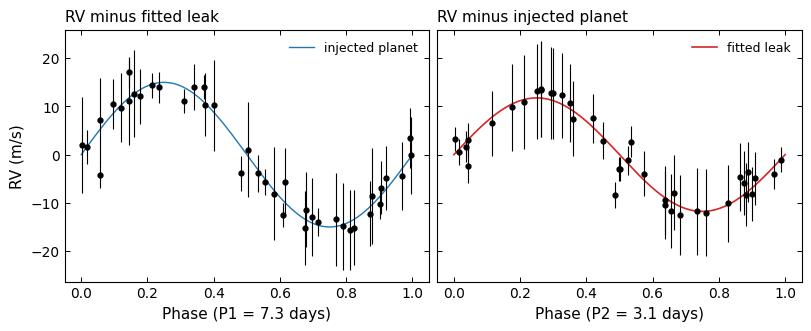

In [6]:
# Fold the RVs at each period with the other signal removed
leak = leak_per_w * (w - 0.5)
phase_grid = np.linspace(0, 1, 200)
fig, axs = plt.subplots(1, 2, figsize=(8, 3.2), sharey=True)
plot_points(axs[0], (t / P1) % 1, (vels - leak - offset) * 1e3, evels * 1e3)
plot_extra(axs[0], phase_grid, K1 * 1e3 * np.sin(2 * np.pi * phase_grid), label="injected planet")
axs[0].set_xlabel(f"Phase (P1 = {P1} days)")
axs[0].set_ylabel("RV (m/s)")
axs[0].set_title("RV minus fitted leak", loc="left")
plot_points(axs[1], (t / P2) % 1, (vels - v_planet - offset) * 1e3, evels * 1e3)
plot_model(axs[1], phase_grid, leak_per_w * A_W * 1e3 * np.sin(2 * np.pi * phase_grid),
           label="fitted leak")
axs[1].set_xlabel(f"Phase (P2 = {P2} days)")
axs[1].set_title("RV minus injected planet", loc="left")
for ax in axs:
    ax.legend(loc="upper right")
plt.show()

**The two distances and the periodograms**: GLS of the RVs, USuRPER of the spectra, and the two
partial periodograms, each also computed *without* its control for comparison.

In [7]:
# Shift distance (RVs) and shape distance (spectra shifted to rest)
def distances(vels, fluxes):
    """Shift distance |v_i - v_j| (km/s) and shape distance (chords of the spectra at rest)."""
    rest_waves = [wv / dsp.doppler_factor(v) for wv, v in zip(waves, vels)]   # exactly at rest
    return scalar_distance_matrix(vels), spectral_distance_matrix(rest_waves, fluxes)

# Ordinary PDC periodogram of one distance matrix
def plain(a):
    """The PDC of one distance matrix: U-centre it and scan."""
    return pdc_power(t, freqs, unbiased_u_centering(a, n))

# Partial periodogram: PDC of a with c projected out
def partial(a, c):
    """The partial periodogram of a, controlling for c."""
    A, C = partial_centering(a, c)
    return pdc_power(t, freqs, A, control=C)

# The two distance matrices
shift_distance, shape_distance = distances(vels, fluxes)
# All periodograms: GLS, USuRPER, and the partial and uncontrolled versions
R = {"GLS of the RVs": LombScargle(t, vels).power(freqs),
     "USuRPER of the spectra": plain(spectral_distance_matrix(waves, fluxes)),
     "PDC of the RVs (no control)": plain(shift_distance),
     "partial: shift": partial(shift_distance, shape_distance),
     "shape, no control": plain(shape_distance),
     "partial: shape": partial(shape_distance, shift_distance)}

# Print a periodogram's highest peak and its power at P1 and P2
def describe(name, power, local_p=True):
    best = np.argmax(power)
    p_text = f", local p = {pdc_pvalue(power[best], n):.0e}" if local_p else ""
    print(f"{name:28s} peak at P = {1 / freqs[best]:6.3f} d (power {power[best]:.2f}{p_text}); "
          f"power at P1 {power_at(freqs, power, P1):+.2f}, at P2 {power_at(freqs, power, P2):+.2f}")

# Report every periodogram
for name, power in R.items():
    describe(name, power, local_p=not name.startswith("GLS"))

GLS of the RVs               peak at P =  7.220 d (power 0.63); power at P1 +0.60, at P2 +0.37
USuRPER of the spectra       peak at P =  3.106 d (power 0.65, local p = 2e-07); power at P1 -0.02, at P2 +0.65
PDC of the RVs (no control)  peak at P =  7.092 d (power 0.40, local p = 3e-05); power at P1 +0.35, at P2 +0.17
partial: shift               peak at P =  7.092 d (power 0.43, local p = 2e-05); power at P1 +0.37, at P2 -0.02
shape, no control            peak at P =  3.106 d (power 0.65, local p = 2e-07); power at P1 -0.03, at P2 +0.65
partial: shape               peak at P =  3.101 d (power 0.64, local p = 3e-07); power at P1 -0.14, at P2 +0.64


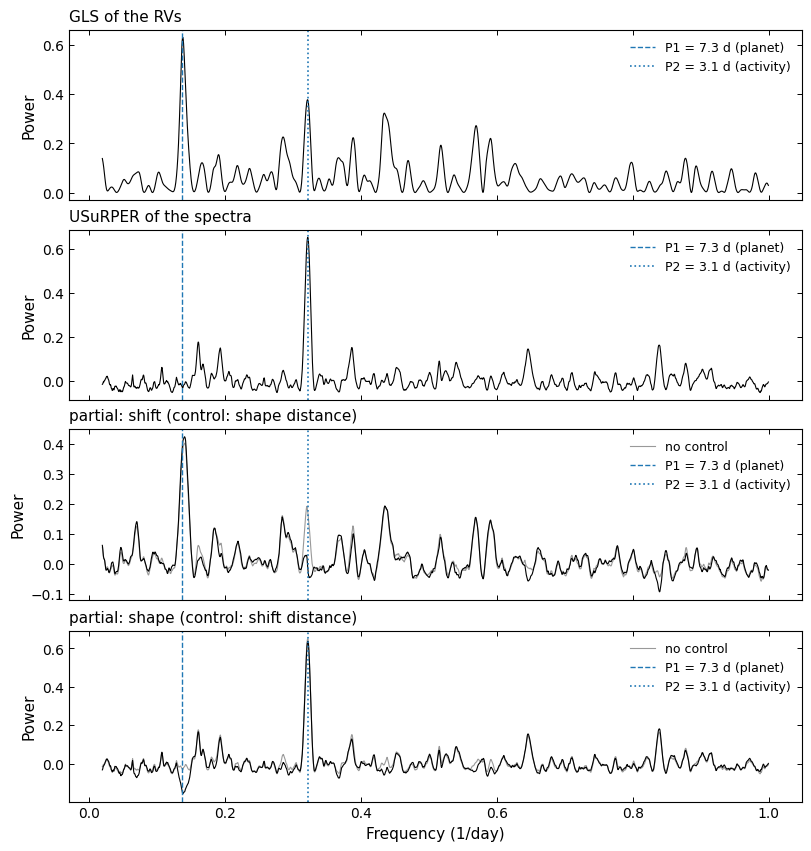

In [8]:
# Plot GLS, USuRPER and the two partial periodograms, each with its uncontrolled version in grey
panels = [("GLS of the RVs", "GLS of the RVs", None),
          ("USuRPER of the spectra", "USuRPER of the spectra", None),
          ("partial: shift", "partial: shift (control: shape distance)", "PDC of the RVs (no control)"),
          ("partial: shape", "partial: shape (control: shift distance)", "shape, no control")]
fig, axs = plt.subplots(4, 1, figsize=(8, 8.4), sharex=True)
for ax, (key, title, uncontrolled) in zip(axs, panels):
    if uncontrolled is not None:
        ax.plot(freqs, R[uncontrolled], color=GREY, lw=0.8, label="no control")
    plot_curve(ax, freqs, R[key], lw=0.8)
    ax.axvline(1 / P1, color=EXTRA_COLOR, ls="--", lw=1, label=f"P1 = {P1} d (planet)")
    ax.axvline(1 / P2, color=EXTRA_COLOR, ls=":", lw=1.2, label=f"P2 = {P2} d (activity)")
    ax.set_ylabel("Power")
    ax.set_title(title, loc="left")
    ax.legend(loc="upper right")
axs[-1].set_xlabel("Frequency (1/day)")
plt.show()

Reading from the top:

- **GLS** has peaks at both periods; nothing says the 3.1-day one is not a second planet.
- **USuRPER** sees only $P_2$: the temperature change alters the spectrum far more than a
  15 m/s shift does.
- **Shift**: $P_1$ stands out (7.09 d, within a peak width), and the $P_2$ peak of the
  uncontrolled PDC (grey, 0.17) drops to −0.02: the leak has been projected out.
- **Shape**: $P_2$ only; the shift to rest already removed the planet, so the control changes
  little (0.65 → 0.64). The −0.14 at $P_1$ is a slight anti-correlation of residuals, not a
  detection.

## 5. Two contrasting stars

The same schedule, noise and template, with one signal at a time: a quiet star with the planet
($w$ fixed at 0.5), and an active star with no planet.

In [9]:
# Two contrasting stars: planet only (w fixed) and activity only (no motion)
cases = {"planet only": (v_planet, np.full_like(t, 0.5)),
         "activity only": (np.zeros_like(t), w)}
results = {}
# Simulate each, measure RVs, and compute all the periodograms
for name, (v_case, w_case) in cases.items():
    fluxes_case = observe(v_case, w_case)
    vels_case, _ = measure_rvs(fluxes_case)
    shift_d, shape_d = distances(vels_case, fluxes_case)
    results[name] = {"GLS": LombScargle(t, vels_case).power(freqs),
                     "PDC": plain(shift_d),
                     "partial: shift": partial(shift_d, shape_d),
                     "partial: shape": partial(shape_d, shift_d)}
    # Report the peaks
    print(f"{name}: RV rms {np.std(vels_case) * 1e3:.1f} m/s")
    for key, power in results[name].items():
        best = np.argmax(power)
        p_text = "" if key == "GLS" else f", local p = {pdc_pvalue(power[best], n):.0e}"
        print(f"  {key:14s} peak at P = {1 / freqs[best]:6.3f} d (power {power[best]:.2f}{p_text}); "
              f"power at P1 {power_at(freqs, power, P1):+.2f}, at P2 {power_at(freqs, power, P2):+.2f}")

planet only: RV rms 10.6 m/s
  GLS            peak at P =  7.273 d (power 0.95); power at P1 +0.94, at P2 +0.02
  PDC            peak at P =  7.246 d (power 0.63, local p = 3e-07); power at P1 +0.62, at P2 -0.02
  partial: shift peak at P =  7.246 d (power 0.63, local p = 3e-07); power at P1 +0.62, at P2 -0.02
  partial: shape peak at P =  2.198 d (power 0.09, local p = 3e-02); power at P1 -0.03, at P2 +0.02


activity only: RV rms 8.4 m/s
  GLS            peak at P =  3.110 d (power 0.92); power at P1 +0.01, at P2 +0.91
  PDC            peak at P =  3.110 d (power 0.61, local p = 4e-07); power at P1 -0.04, at P2 +0.59
  partial: shift peak at P =  3.150 d (power 0.22, local p = 2e-03); power at P1 -0.03, at P2 +0.05
  partial: shape peak at P =  3.086 d (power 0.37, local p = 8e-05); power at P1 +0.02, at P2 +0.33


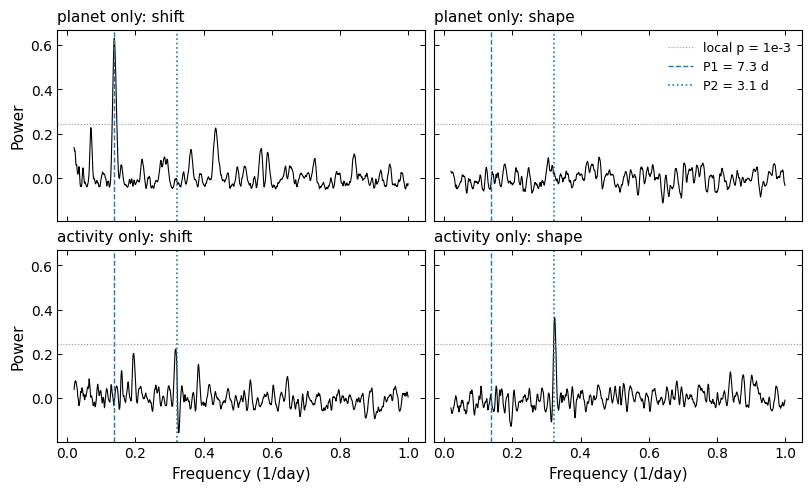

In [10]:
# Plot the partial periodograms of both stars with the local p = 1e-3 level
level = pdc_power_level(1e-3, n)
fig, axs = plt.subplots(2, 2, figsize=(8, 4.8), sharex=True, sharey=True)
for row, (name, res) in zip(axs, results.items()):
    for ax, key in zip(row, ("partial: shift", "partial: shape")):
        plot_curve(ax, freqs, res[key], lw=0.8)
        ax.axhline(level, color=GREY, ls=":", lw=0.8, label="local p = 1e-3")
        ax.axvline(1 / P1, color=EXTRA_COLOR, ls="--", lw=1, label=f"P1 = {P1} d")
        ax.axvline(1 / P2, color=EXTRA_COLOR, ls=":", lw=1.2, label=f"P2 = {P2} d")
        ax.set_title(f"{name}: {key.split(': ')[1]}", loc="left")
    row[0].set_ylabel("Power")
for ax in axs[-1]:
    ax.set_xlabel("Frequency (1/day)")
axs[0, 1].legend(loc="upper right")
plt.show()

- **Planet only**: shift finds $P_1$; shape has no significant peak.
- **Activity only**: GLS and the plain PDC find 3.1 days, a false planet (PDC 0.61). Shift keeps
  a weak bump (0.22, local p = 2e-3, not significant with ~85 independent frequencies), the
  non-linear remainder of the toy. Shape finds $P_2$ with less power than in section 4 (0.37
  against 0.64): the RVs now follow the shape change, so the control removes part of the shape
  signal too ([periodograms § partial periodograms](../../docs/periodograms.md#partial-periodograms-shift-and-shape-binnenfeld-et-al-2022)).

## 6. How far to trust them

What the partial periodograms need and cannot do is listed in
[limitations § periodograms](../../docs/limitations.md#periodograms). Their p-values (`pdc_pvalue`) are local and derived for the
distance correlation, not for the partial statistic ([periodograms § p-values](../../docs/periodograms.md#p-values)).
A check on our data: permute the epochs' times, which destroys any periodicity, and count how
often the partial power at 0.2/day exceeds each level (`pdc_power_level`).

In [11]:
# Null test: permute the epoch times, which destroys periodicity, at 0.2/day
levels = pdc_power_level([0.05, 0.01], n)
perm = np.random.default_rng(1)
# How often does the partial power exceed the p = 0.05 and 0.01 levels?
for name, (a, c) in {"shift": (shift_distance, shape_distance),
                     "shape": (shape_distance, shift_distance)}.items():
    A, C = partial_centering(a, c)
    null = np.array([pdc_power(perm.permutation(t), [0.2], A, control=C)[0] for _ in range(4000)])
    print(f"partial {name}: exceeds the p = 0.05 level in {np.mean(null > levels[0]):.3f}, "
          f"the p = 0.01 level in {np.mean(null > levels[1]):.4f} of 4000 permutations")

partial shift: exceeds the p = 0.05 level in 0.045, the p = 0.01 level in 0.0043 of 4000 permutations
partial shape: exceeds the p = 0.05 level in 0.047, the p = 0.01 level in 0.0060 of 4000 permutations


Here the levels hold, slightly conservatively at 0.01: one data set at one frequency, not a
proof. Confirm a candidate by a permutation test like this one, or by injection and recovery.

**Twice the period.** A PDC-type periodogram also responds, weakly, at twice a sinusoid's period
([periodograms § PDC](../../docs/periodograms.md#pdc-phase-distance-correlation-zucker-2018)). The noiseless planet RVs
on this schedule:

In [12]:
# Noiseless planet RVs: PDC power at P1 and at twice P1
quiet = plain(scalar_distance_matrix(v_planet))
for label, period in ((f"P1 = {P1} d", P1), (f"2 P1 = {2 * P1} d", 2 * P1)):
    print(f"PDC of the noiseless planet RVs at {label:12s}: {power_at(freqs, quiet, period):.2f}")
print(f"planet-only shift periodogram (section 5) at 2 P1: "
      f"{power_at(freqs, results['planet only']['partial: shift'], 2 * P1):.2f}")

PDC of the noiseless planet RVs at P1 = 7.3 d  : 0.66
PDC of the noiseless planet RVs at 2 P1 = 14.6 d: 0.24
planet-only shift periodogram (section 5) at 2 P1: 0.22


The shift periodogram inherits this: the peak near 0.07/day in the planet-only panel of section 5.
On other schedules it can rival the true peak; check $P$ against $2P$ before believing a long
period.

## The same numbers with the objects

`PeriodicityDetector.calc_partial_periodogram` and `calc_usurper` compose exactly these atoms, so
USuRPER and the p-value levels are identical, bit for bit. The RVs come from
`calc_rv_against_template`, a different code path (notebook 03), so they and the periodograms
built on them are compared to $10^{-9}$. [howto/04_find_periods](../howto/04_find_periods.ipynb)
is the short recipe.

In [13]:
# Objects: the same analysis through Observations and PeriodicityDetector
from sparta import Observations, Spectrum, Template, TimeSeries

# Ingest the same spectra and measure RVs against the same template
obs = Observations(time_series=TimeSeries(times=list(t),
                                          vals=[Spectrum(wv=[pixels.copy()], sp=[f]) for f in fluxes]))
obs.calc_rv_against_template(Template.from_arrays(fine, mean_flux), dv=0.1, vel_bound=30)
# RVs must agree to 1e-9 km/s
assert np.allclose(obs.vels, vels, rtol=0, atol=1e-9)           # km/s

# Compute every periodogram with the detector
obs.init_periodicity_detector(freq_range=(0.02, 1.0), periodogram_grid_resolution=2000)
pd = obs.periodicity_detector
pd.calc_gls()
pd.calc_pdc()
pd.calc_usurper()
pd.calc_partial_periodogram("shift")
pd.calc_partial_periodogram("shape")
# USuRPER and p-value levels must be identical, the rest to 1e-9
assert np.array_equal(pd.frequency_grid, freqs)
assert np.array_equal(pd.results_power["USURPER_unbiased"], R["USuRPER of the spectra"])
assert np.array_equal(pd.calc_pdc_pval([0.05, 0.01], inverse_sf=True), levels)
# Detector result keys against the plain-array results
pairs = {"GLS": "GLS of the RVs", "PDC_unbiased": "PDC of the RVs (no control)",
         "partial_shift": "partial: shift", "partial_shape": "partial: shape"}
for key, name in pairs.items():
    assert np.allclose(pd.results_power[key], R[name], rtol=0, atol=1e-9)
print("USuRPER and the p-value levels: identical")
print(f"RVs differ by at most {np.max(np.abs(obs.vels - vels)):.1e} km/s; GLS, PDC and the partial "
      f"periodograms by at most {max(np.max(np.abs(pd.results_power[k] - R[m])) for k, m in pairs.items()):.1e}")

USuRPER and the p-value levels: identical
RVs differ by at most 0.0e+00 km/s; GLS, PDC and the partial periodograms by at most 0.0e+00


## Summary / next

- Line-shape changes leak into the RVs at their own period (11 m/s at 3.1 d here); the GLS of the
  RVs cannot tell the leak from a planet.
- `partial_centering`, `norm_z` and `inner_prod` project a control out of two U-centred distance
  matrices and correlate the rest (toy: 0.91 → 0.05 when the only link was the control).
- `pdc_power(..., control=...)`: *shift* found the planet and removed the activity's RV peak;
  *shape* found the activity without the planet. With no planet, a weak residue of the leak
  remained.
- The p-values are local and borrowed from the distance correlation; a permutation check held.

**Next:** [`09_end_to_end`](09_end_to_end.ipynb): from simulated spectra to RVs, a periodogram
and a fitted orbit, in one chain.